# Análisis exploratorio de eventos Wyscout

Los datos corresponden a la temporada 2017/18 e incluyen los 380 partidos de la Premier League. Ademas contiene 643.150 eventos.

**Contenido**
1. Configuración
2. Carga de datos
3. Vista general de los eventos
4. Futbolistas por posición
5. Acciones por jugador
6. Subeventos

> Para analizar otro torneo, cambia `TORNEO` en la sección 1 y vuelve a ejecutar el cuaderno.

## 1. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from analisis_exploratorio import contar_acciones_por_jugador, contar_subeventos
from cargar_eventos import cargar_eventos, cargar_jugadores

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 12)

CARPETA_BASE = Path.cwd()
CARPETA_DATOS = CARPETA_BASE / "data" / "events"
TORNEO = "England"  # Italy, England, Germany, France, Spain, European_Championship, World_Cup
ARCHIVO_EVENTOS = CARPETA_DATOS / f"events_{TORNEO}.json"
ARCHIVO_JUGADORES = CARPETA_BASE / "data" / "players.json"

print(f"Torneo: {TORNEO}")
print(f"Eventos:   {ARCHIVO_EVENTOS.name}")
print(f"Jugadores: {ARCHIVO_JUGADORES.name}")

Torneo: England
Eventos:   events_England.json
Jugadores: players.json


## 2. Carga de datos

Se cargan los eventos del torneo y el catálogo de jugadores. El nombre de cada jugador se añade a la tabla de eventos a partir de su `playerId`; los eventos sin jugador se etiquetan como `Sin identificar`.

In [2]:
eventos, df_eventos = cargar_eventos(ARCHIVO_EVENTOS)
df_jugadores = cargar_jugadores(ARCHIVO_JUGADORES)

nombres_jugadores = df_jugadores.set_index("wyId")["playerName"]
df_eventos["playerName"] = (
    df_eventos["playerId"].map(nombres_jugadores).fillna("Sin identificar")
)

print(f"Eventos cargados: {len(eventos):,}")
print(f"Jugadores en el catálogo: {len(df_jugadores):,}")

Eventos cargados: 643,150
Jugadores en el catálogo: 3,603


## 3. Vista general de los eventos

In [3]:
print(f"Dimensiones de la tabla: {df_eventos.shape[0]:,} filas x {df_eventos.shape[1]} columnas")
print("\nColumnas disponibles:")
print(", ".join(df_eventos.columns))
print("\nVariables del dataframe de jugadores:")
print(", ".join(df_jugadores.columns))

Dimensiones de la tabla: 643,150 filas x 13 columnas

Columnas disponibles:
eventId, subEventName, tags, playerId, positions, matchId, eventName, teamId, matchPeriod, eventSec, subEventId, id, playerName

Variables del dataframe de jugadores:
passportArea, weight, firstName, middleName, lastName, currentTeamId, birthDate, height, role, birthArea, wyId, foot, shortName, currentNationalTeamId, playerName, position


In [4]:
df_eventos.head()

,eventId,subEventName,tags,playerId,positions,matchId,...,teamId,matchPeriod,eventSec,subEventId,id,playerName
0,8,Simple pass,[{'id': 1801}],25413,"[{'y': 49, 'x': 49}, {'y': 78, 'x': 31}]",2499719,...,1609,1H,2.758649,85,177959171,Alexandre Lacazette
1,8,High pass,[{'id': 1801}],370224,"[{'y': 78, 'x': 31}, {'y': 75, 'x': 51}]",2499719,...,1609,1H,4.946850,83,177959172,Rob Holding
2,8,Head pass,[{'id': 1801}],3319,"[{'y': 75, 'x': 51}, {'y': 71, 'x': 35}]",2499719,...,1609,1H,6.542188,82,177959173,Mesut \u00d6zil
3,8,Head pass,[{'id': 1801}],120339,"[{'y': 71, 'x': 35}, {'y': 95, 'x': 41}]",2499719,...,1609,1H,8.143395,82,177959174,Mohamed Naser Elsayed Elneny
4,8,Simple pass,[{'id': 1801}],167145,"[{'y': 95, 'x': 41}, {'y': 88, 'x': 72}]",2499719,...,1609,1H,10.302366,85,177959175,H\u00e9ctor Beller\u00edn Moruno


## 4. Futbolistas por posición

El catálogo `players.json` contiene jugadores de todas las ligas, así que se filtra a quienes tienen al menos un evento en el torneo seleccionado.

In [5]:
ids_torneo = df_eventos["playerId"].dropna().unique()
df_jugadores_torneo = df_jugadores[df_jugadores["wyId"].isin(ids_torneo)]
futbolistas_por_posicion = df_jugadores_torneo["position"].value_counts().sort_index()

print(f"Futbolistas de {TORNEO} por posición:")
for posicion, cantidad in futbolistas_por_posicion.items():
    print(f"  {posicion}: {cantidad:,}")

Futbolistas de England por posición:
  Defender: 177
  Forward: 108
  Goalkeeper: 38
  Midfielder: 191


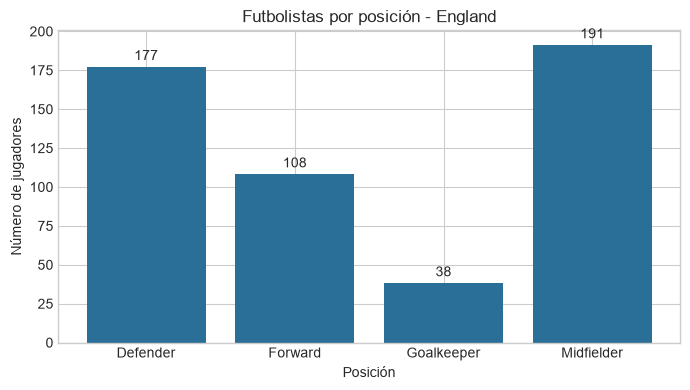

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(futbolistas_por_posicion.index, futbolistas_por_posicion.values, color="#2a6f97")
ax.bar_label(barras, padding=3)
ax.set_title(f"Futbolistas por posición - {TORNEO}")
ax.set_xlabel("Posición")
ax.set_ylabel("Número de jugadores")
plt.tight_layout()
plt.show()

## 5. Acciones por jugador

Se cuentan los eventos de cada jugador identificado (se excluyen `playerId` nulos o 0).

In [7]:
acciones_por_jugador = contar_acciones_por_jugador(df_eventos)

if acciones_por_jugador.empty:
    print("No hay eventos con un jugador identificado.")
else:
    minimo = acciones_por_jugador.min()
    maximo = acciones_por_jugador.max()
    jugadores_minimo = acciones_por_jugador[acciones_por_jugador == minimo].index.tolist()
    jugadores_maximo = acciones_por_jugador[acciones_por_jugador == maximo].index.tolist()

    print(f"Jugadores con al menos una acción: {len(acciones_por_jugador):,}")
    print(f"Media: {acciones_por_jugador.mean():,.2f} acciones por jugador")
    print(f"Máximo: {maximo:,} acciones")
    for player_id in jugadores_maximo:
        print(f"  {nombres_jugadores.get(player_id, 'Nombre no encontrado')} (playerId: {player_id})")
    print(f"Mínimo: {minimo:,} acciones")
    for player_id in jugadores_minimo:
        print(f"  {nombres_jugadores.get(player_id, 'Nombre no encontrado')} (playerId: {player_id})")

Jugadores con al menos una acción: 514
Media: 1,157.82 acciones por jugador
Máximo: 4,060 acciones
  Granit Xhaka (playerId: 49876)
Mínimo: 1 acciones
  Vincent Janssen (playerId: 269676)
  Dwight McNeil (playerId: 532949)


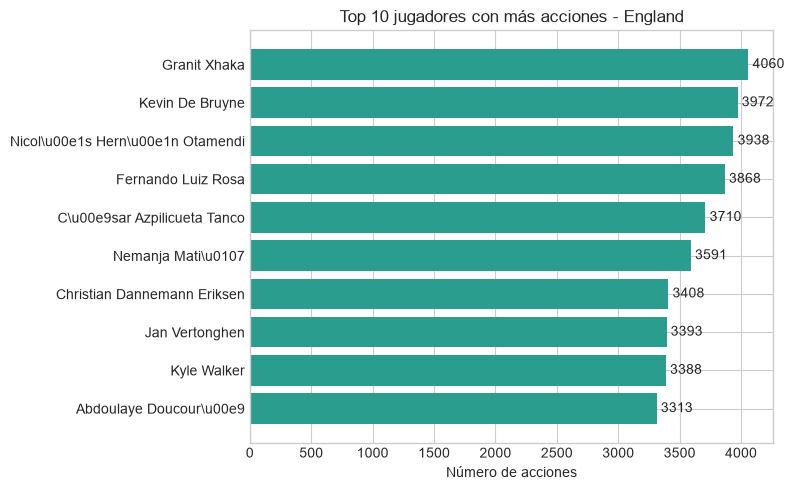

In [8]:
top_jugadores = acciones_por_jugador.nlargest(10).sort_values()
etiquetas = [nombres_jugadores.get(pid, str(pid)) for pid in top_jugadores.index]

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.barh(etiquetas, top_jugadores.values, color="#2a9d8f")
ax.bar_label(barras, padding=3)
ax.set_title(f"Top 10 jugadores con más acciones - {TORNEO}")
ax.set_xlabel("Número de acciones")
plt.tight_layout()
plt.show()

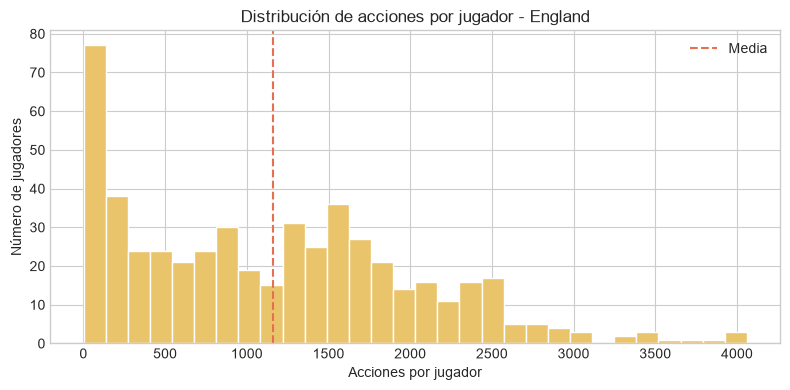

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(acciones_por_jugador.values, bins=30, color="#e9c46a", edgecolor="white")
ax.axvline(acciones_por_jugador.mean(), color="#e76f51", linestyle="--", label="Media")
ax.set_title(f"Distribución de acciones por jugador - {TORNEO}")
ax.set_xlabel("Acciones por jugador")
ax.set_ylabel("Número de jugadores")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Subeventos

Frecuencia de cada tipo de subevento (`subEventName`).

In [10]:
subeventos = contar_subeventos(df_eventos)

print(f"Tipos de subevento distintos: {len(subeventos):,}")
print(f"Registros con nombre de subevento: {subeventos.sum():,}")
subeventos.sort_values(ascending=False).rename("frecuencia").to_frame()

Tipos de subevento distintos: 35
Registros con nombre de subevento: 641,592


,frecuencia
subEventName,
Simple pass,251405
Ground attacking duel,53859
Ground defending duel,53737
Air duel,37760
Touch,34409
Ground loose ball duel,31332
Ball out of the field,27331
High pass,25067
Head pass,21332


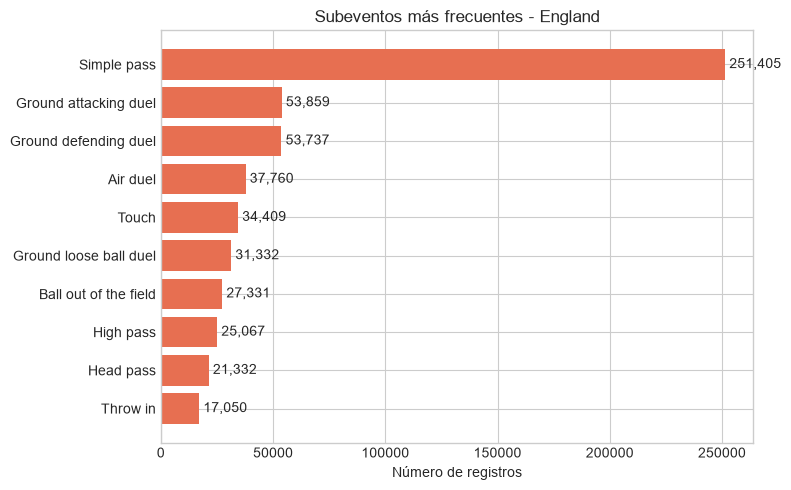

In [11]:
top_subeventos = subeventos.nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.barh(top_subeventos.index, top_subeventos.values, color="#e76f51")
ax.bar_label(barras, padding=3, fmt="{:,.0f}")
ax.set_title(f"Subeventos más frecuentes - {TORNEO}")
ax.set_xlabel("Número de registros")
plt.tight_layout()
plt.show()

In [2]:
import json
import pandas as pd

with ARCHIVO_EVENTOS.open(encoding="utf-8") as f:
    eventos = json.load(f)

tags2name = pd.read_csv(CARPETA_BASE / "data" / "tags2name.csv", sep=";").set_index("Tag")["Description"]

tags_por_subevento = {}
for e in eventos:
    tags_por_subevento.setdefault(e["subEventName"] or "(vacío)", set()).update(t["id"] for t in e["tags"])

df_subeventos_tags = pd.DataFrame(
    [
        {
            "subevento": nombre,
            "tags": [f"{t} ({tags2name.get(t, '?')})" for t in sorted(tags)],
        }
        for nombre, tags in sorted(tags_por_subevento.items())
    ]
)
df_subeventos_tags

,subevento,tags
0,(vacío),[1901 (Counter attack)]
1,Acceleration,"[1401 (Interception), 1801 (Accurate), 1802 (N..."
2,Air duel,"[301 (Assist), 302 (Key pass), 701 (Lost), 702..."
3,Ball out of the field,[]
4,Clearance,"[102 (Own goal), 1001 (Fairplay), 1401 (Interc..."
5,Corner,"[201 (Opportunity), 301 (Assist), 302 (Key pas..."
6,Cross,"[301 (Assist), 302 (Key pass), 401 (Left foot)..."
7,Foul,"[1701 (Red card), 1702 (Yellow card), 1703 (Se..."
8,Free Kick,"[301 (Assist), 302 (Key pass), 1801 (Accurate)..."
9,Free kick cross,"[301 (Assist), 302 (Key pass), 801 (High), 180..."
